# **4.10 Hands-On Kaggle Competition: Predicting Housing Prices**
In the previous sections, we learned some basic tools for training deep neural networks and techniques for network regularization (such as weight decay and backpropagation). In this section, we will put what we’ve learned into practice through a Kaggle competition. The Kaggle House Price Prediction competition is a great place to start. This dataset was collected by Bartde
Cock in 2011 (De Cock, 2011) and covers housing prices in the city of Ames, Arizona, from 2006 to 2010. This dataset is
fairly straightforward and does not require the use of complex model architectures. It is much larger than Harrison and Rubinfeld’s Boston Housing Prices 71 dataset and also has more features.<br><br>
In this section, we will provide a detailed overview of data preprocessing, model design, and hyperparameter selection. Through hands-on practice, you will gain firsthand experience that will benefit your career growth as a data scientist.

## **4.10.1 Download and Cache Datasets**
Throughout this book, we will download various datasets and train and test models. Here, we implement several functions to facilitate data downloads. First, we create a dictionary called `DATA_HUB`, which maps strings representing dataset names to tuples associated with those datasets. Each tuple contains the dataset’s URL and the SHA-1 key used to verify the file’s integrity. All such datasets are hosted on the site at `DATA_URL`.

In [329]:
import hashlib
import os
import tarfile
import zipfile
import requests

#@save
DATA_HUB = dict()
DATA_URL = 'http://d2l-data.s3-accelerate.amazonaws.com/'

The `download` function below is used to download a dataset, cache it in a local directory (by default, `../data`), and return the name of the downloaded file. If the dataset file already exists in the cache directory and its SHA-1 hash matches the one stored in DATA_HUB, we will use the cached file to avoid downloading it again.

In [330]:
def download(name, cache_dir=os.path.join('..', 'data')): #@save
    """Download a file from DATA_HUB and return the local filename"""
    assert name in DATA_HUB, f"{name} does not exist in {DATA_HUB}"
    url, sha1_hash = DATA_HUB[name]
    os.makedirs(cache_dir, exist_ok=True)
    file_name = os.path.join(cache_dir, url.split('/')[-1])
    if os.path.exists(file_name):
        sha1 = hashlib.sha1()
        with open(file_name, 'rb') as f:
            while True:
                data = f.read(1048576)
                if not data:
                    break
                sha1.update(data)
        if sha1.hexdigest() == sha1_hash:
            return file_name # Cache Hit
    print(f'Downloading {file_name} from {url}...')
    r = requests.get(url, stream=True, verify=True)
    with open(file_name, 'wb') as f:
        f.write(r.content)
    return file_name

We also need to implement two utility functions: one that downloads and extracts a ZIP or TAR file, and another that downloads all the datasets used in this book from DATA_HUB to the cache directory.

In [331]:
def download_extract(name, folder=None): #@save
    """Download and extract the zip/tar file"""
    file_name = download(name)
    base_dir = os.path.dirname(file_name)
    data_dir, ext = os.path.splitext(file_name)
    if ext == '.zip':
        fp = zipfile.ZipFile(file_name, 'r')
    elif ext in ('.tar', '.gz'):
        fp = tarfile.open(file_name, 'r')
    else:
        assert False, 'Only zip/tar files can be extracted'
    fp.extractall(base_dir)
    return os.path.join(base_dir, folder) if folder else data_dir

def download_all(): #@save
    """Download all files from DATA_HUB"""
    for name in DATA_HUB:
        download(name)

## **4.10.2 Kaggle**
Kaggle is a popular platform for hosting machine learning competitions today, with each competition centered around at least one dataset. Many competitions have sponsors who offer cash prizes for winning solutions. The platform helps users interact through forums and code sharing, fostering both collaboration and competition. Although the pursuit of high rankings on leaderboards can often lead to irrational behavior—some researchers focus narrowly on preprocessing steps rather than considering fundamental issues. However, an objective platform holds immense value: it facilitates direct, quantitative comparisons between competing methods, as well as code sharing. This makes it easy for everyone to learn which methods work and which do not.

## **4.10.3 Accessing and Reading Datasets**
Note that the competition data is divided into a training set and a test set. Each record includes property values and attributes such as street type, year of construction, roof type, and basement condition. These features consist of various data types. For example, the year of construction is represented by an integer, the roof type by a discrete category, and other features by floating-point numbers. This is where reality complicates matters: for example, some data is completely missing, and missing values are simply marked as “NA.” The price of each house appears only in the training set (after all, this is a competition). We would like to split the training set to create a validation set, but after uploading our predictions to Kaggle, we can only evaluate our model on the official test set.<br><br>
Before we begin, we’ll use pandas to read and process the data—a library we introduced in [Section 2.2](../../chapter_preliminaries/content/data_pre_processing.ipynb#22-data-pre-processing). Therefore, before proceeding, we need to make sure pandas is installed. Fortunately, if you’re reading this book in Jupyter, you can install pandas without leaving the notebook.

In [332]:
%matplotlib
import numpy as np
import pandas as pd
import torch
from torch import nn
from d2l import torch as d2l

Using matplotlib backend: module://matplotlib_inline.backend_inline


For convenience, we can use the script defined above to download and cache the Kaggle Housing dataset.

In [333]:
DATA_HUB['kaggle_house_train'] = ( #@save
DATA_URL + 'kaggle_house_pred_train.csv',
'585e9cc93e70b39160e7921475f9bcd7d31219ce')
DATA_HUB['kaggle_house_test'] = ( #@save
DATA_URL + 'kaggle_house_pred_test.csv',
'fa19780a7b011d9b009e8bff8e99922a8ee2eb90')

We use pandas to load two CSV files containing the training and test data, respectively.

In [334]:
train_data = pd.read_csv(download('kaggle_house_train', cache_dir=os.path.join('..','..','data')))
test_data = pd.read_csv(download('kaggle_house_test', cache_dir=os.path.join('..','..','data')))

The training dataset consists of 1,460 samples, each with 80 features and 1 label, while the test dataset consists of 1,459 samples, each with 80 features.

In [335]:
print(train_data.shape)
print(test_data.shape)

(1460, 81)
(1459, 80)


Let's take a look at the first four and last two features, as well as their corresponding labels (house prices).

In [336]:
print(train_data.iloc[0:4, [0, 1, 2, 3,-3,-2,-1]])

   Id  MSSubClass MSZoning  LotFrontage SaleType SaleCondition  SalePrice
0   1          60       RL     65.00000       WD        Normal     208500
1   2          20       RL     80.00000       WD        Normal     181500
2   3          60       RL     68.00000       WD        Normal     223500
3   4          70       RL     60.00000       WD       Abnorml     140000


As we can see, in each sample, the first feature is the ID, which helps the model identify each training sample. While this is convenient, it does not contain any information useful for making predictions. Therefore, before feeding the data to the model, we remove it from the dataset.

In [337]:
all_features = pd.concat((train_data.iloc[:, 1:-1], test_data.iloc[:, 1:]))

## **4.10.4 Data Preprocessing**
As mentioned above, we have a variety of data types. Before we begin modeling, we need to preprocess the data. **First, we will replace all missing values with the mean of the corresponding feature. Then, to bring all features onto a common scale, we will standardize the data by rescaling the features to have a mean of zero and a variance of one**:
##### **(4.10.1)**
$$x \leftarrow \frac{x-\mu}{\sigma}$$
Here, $\mu$ and $\sigma$ represent the mean and standard deviation, respectively. Now, these features have a mean of zero and a variance of one, that is, $E[\frac{x − \mu}{\sigma}] = \mu − \mu\sigma = 0$ and $E[(x −\mu)^{2}] = (\sigma^{2} + \mu^{2}) − 2\mu^{2} + \mu^{2} = σ²$. **Intuitively, there are two reasons why we standardize the data: first, it facilitates optimization. Second, since
we do not know which features are correlated, we do not want the penalty assigned to the coefficient of one feature to be greater than that assigned to the coefficient of any other feature**.

In [338]:
# If test data is not available, the mean and standard deviation can be calculated based on the training data
numeric_features = all_features.select_dtypes(include='number').columns
print(numeric_features)
all_features[numeric_features] = all_features[numeric_features].apply(
    lambda x: (x - x.mean()) / (x.std() + 1e-7))
# After standardizing the data, all means disappear, so we can set the missing values to 0
all_features[numeric_features] = all_features[numeric_features].fillna(0)

Index(['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond',
       'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
       'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
       'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath',
       'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces',
       'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF',
       'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal',
       'MoSold', 'YrSold'],
      dtype='str')


Next, we handle discrete values. This includes features such as “MSZoning.” We replace them with one-hot encoding, using the same method as we did earlier to convert multiclass labels into vectors (see [Section 3.4.1](../../chapter_linear_neural_network/content/softmax_regression.ipynb#341-classification-problems)). For example, “MSZoning” contains the values “RL” and “Rm.” We will create two new indicator features, “MSZoning_RL” and “MSZoning_RM,” with values of 0 or 1. Under one-hot encoding, if the original value of “MSZoning” is “RL,” then “MSZoning_RL” is 1 and “MSZoning_RM” is 0. The pandas package automatically implements this for us.

In [339]:
# “Dummy_na=True” treats “na” (missing values) as valid feature values and creates dummy features for them
all_features = pd.get_dummies(all_features, dummy_na=True)
bool_cols = all_features.select_dtypes(include='bool').columns
all_features[bool_cols] = all_features[bool_cols].astype(int)
all_features.shape

(2919, 330)

As you can see, this transformation increases the total number of features from 79 to 330. Finally, using the `values` attribute, we can extract the NumPy format from the pandas format and convert it to a tensor representation for training.

In [340]:
n_train = train_data.shape[0]
train_features = torch.tensor(all_features[:n_train].values, dtype=torch.float32)
test_features = torch.tensor(all_features[n_train:].values, dtype=torch.float32)
train_labels = torch.tensor(
    train_data.SalePrice.values.reshape(-1, 1), dtype=torch.float32)
train_labels = torch.log(train_labels)

## **4.10.5 Training**
**First, we train a linear model using the squared loss function. Obviously, a linear model is unlikely to win the competition, but it serves as a soundness check to determine whether there is meaningful information in the data.** If we cannot perform better than random guessing here, then we likely have made an error in data processing. If all goes well, the linear model will serve as a baseline, giving us an intuitive sense of how much better the best model performs compared to a simple model.

In [341]:
loss = nn.MSELoss()
in_features = train_features.shape[1]

def get_net():
    net = nn.Sequential(nn.Linear(in_features, 1))
    return net

Just like stock prices, what matters with housing prices is the relative value, not the absolute value. Therefore, we are more concerned with the relative error $\frac{y − \hat{y}}{y}$ than with the absolute error $y − \hat{y}$. For example, suppose we estimate the price of a house in a rural area of Ohio and our prediction is off by \\$100,000, but the typical house there is worth \\$125,000; in that case, the model is likely performing poorly. On the other hand, if our prediction shows the same \\$100,000 bias in a luxury housing area in California (where the median home price exceeds \\$4 million), it might actually be a good prediction.<br><br>
One way to address this issue is to measure the difference using the logarithm of the price prediction. In fact, this is also the error metric officially used in the competition to evaluate the quality of submissions. Specifically, $\delta$ is transformed from $|log\,y − log\,\hat{y}| ≤ \delta$ to $e^{−\delta} \lt \frac{\hat{y}}{y} ≤ e^{\delta}$. This results in the following root-mean-square error between the logarithm of the predicted price and the logarithm of the true label price:
##### **(4.10.2)**
$$\sqrt{\frac{1}{n} \sum\limits^{n}_{i=1}(log\, y_i -  log \, \hat{y}_i)^2}$$

In [342]:
def log_rmse(net, features, labels):
    # To further stabilize this value when taking the logarithm, set values less than 1 to 1.
    clipped_preds = torch.clamp(net(features), 1, float('inf'))
    rmse = torch.sqrt(loss(torch.log(clipped_preds), torch.log(labels)))

    return rmse.item()

Unlike in the previous sections, our training function will use the Adam optimizer (which we will describe in more detail in later chapters). The main advantage of the Adam optimizer is that it is less sensitive to the initial learning rate.

In [343]:
def train(net, train_features, train_labels, test_features, test_labels, num_epochs, learning_rate, weight_decay, batch_size):
    train_ls, test_ls = [], []
    train_iter = d2l.load_array((train_features, train_labels), batch_size)
    optimizer = torch.optim.Adam(net.parameters(), lr=learning_rate, weight_decay=weight_decay)

    for epoch in range(num_epochs):
        for X, y in train_iter:
            optimizer.zero_grad()
            l = loss(net(X), y)
            l.backward()
            optimizer.step()
        train_ls.append(log_rmse(net, train_features, train_labels))
        if test_labels is not None:
            test_ls.append(log_rmse(net, test_features, test_labels))
    return train_ls, test_ls

## **4.10.6 K-fold Cross-Validation**
The section on model selection [(Section 4.4)](./model_selection_under_over_fit.ipynb#44-model-selection-underfitting-and-overfitting) in this book introduces K-fold cross-validation, which aids in model selection and hyperparameter tuning. First, we need to define a function that returns the data from the i-th fold during the K-fold cross-validation process. Specifically, it selects the i-th slice as the validation data, with the remainder serving as the training data. **Note that this is not the most efficient way to handle the data; if our dataset is much larger, there are other solutions**.

In [344]:
def get_k_gold_data(k, i, X, y):
    assert k > 1
    fold_size = X.shape[0] // k
    X_train, y_train = None, None
    X_valid, y_valid = None, None
    for j in range(k):
        idx = slice(j * fold_size, (j + 1) * fold_size)
        X_part, y_part = X[idx, :], y[idx]
        if j == i:
            X_valid, y_valid = X_part, y_part
        elif X_train is None:
            X_train, y_train = X_part, y_part
        else:
            X_train = torch.cat([X_train, X_part], 0)
            y_train = torch.cat([y_train, y_part], 0)
    return X_train, y_train, X_valid, y_valid

After training K times in K-fold cross-validation, return the average of the training and validation errors.

In [345]:
def k_fold(k, X_train, y_train, num_epochs, learning_rate, weight_decay, batch_size):
    train_l_sum, valid_l_sum = 0, 0
    for i in range(k):
        data = get_k_gold_data(k, i, X_train, y_train)
        net = get_net()
        train_ls, valid_ls = train(net, *data, num_epochs, learning_rate, weight_decay, batch_size)
        train_l_sum += train_ls[-1]
        valid_l_sum += valid_ls[-1]
        if i == 0:
            d2l.plot(list(range(1, num_epochs + 1)), [train_ls, valid_ls],
                     xlabel='epoch', ylabel='rmse', xlim=[1, num_epochs],
                     legend=['train', 'valid'], yscale='log')
        print(f'Fold {i + 1}, train log rmse{float(train_ls[-1]):f},'
              f' valid log rmse{float(valid_ls[-1]):f}')
    return train_l_sum / k, valid_l_sum / k

## **4.10.7 Model Selection**
In this example, we have selected a set of unoptimized hyperparameters and leave it to the reader to improve the model. Finding a set of optimized hyperparameters may take time, depending on how many variables one is optimizing. With a sufficiently large dataset and reasonably set hyperparameters, K-fold cross-validation tends to show considerable stability across multiple runs. However, if we try unreasonable hyperparameters, we may find that the validation results no longer represent the true error.

Fold 1, train log rmse0.017258, valid log rmse0.018066
Fold 2, train log rmse0.016830, valid log rmse0.019615
Fold 3, train log rmse0.016918, valid log rmse0.018613
Fold 4, train log rmse0.016323, valid log rmse0.017275
Fold 5, train log rmse0.016879, valid log rmse0.023970
Fold 5, average train log rmse0.016842,average valid log rmse0.019508


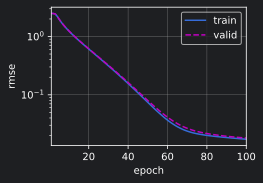

In [346]:
k, num_epochs, lr, weight_decay, batch_size = 5, 100, 5e-4, 0, 64
train_l, valid_l = k_fold(k, train_features, train_labels, num_epochs, lr, weight_decay, batch_size)
print(f'Fold {k}, average train log rmse{float(train_l):f},'
      f'average valid log rmse{float(valid_l):f}')

Please note that sometimes the training error for a set of hyperparameters may be very low, but the K-fold cross-validation error may be much higher, indicating that the model is overfitting. Throughout the training process, we want to monitor both the training error and the validation error. **Less overfitting may indicate that the available data can support a more powerful model, while greater overfitting may mean that we can benefit from regularization techniques**.

## **4.10.8 Submit a Kaggle Prediction**
Now that we know which hyperparameters to choose, we might as well train the model using the entire dataset (rather than just the 1−1/K data used in cross-validation). The model we obtain in this way can then be applied to the test set. Saving the predictions in a CSV file simplifies the process of uploading the results to Kaggle.

In [347]:
def train_and_pred(train_features, test_features, train_labels, test_data,
                   num_epochs, lr, weight_decay, batch_size):
    net = get_net()
    train_ls, _ = train(net, train_features, train_labels, None, None,
                        num_epochs, lr, weight_decay, batch_size)
    d2l.plot(np.arange(1, num_epochs + 1), [train_ls], xlabel='epoch',
             ylabel='log rmse', xlim=[1, num_epochs], yscale='log')
    print(f'train log rmse: {float(train_ls[-1]):f}')
    # Apply the network to the test set.
    preds = net(test_features).detach().numpy()
    # Reformat it to export to Kaggle
    test_data['SalePrice'] = pd.Series(preds.reshape(1, -1)[0])
    submission = pd.concat([test_data['Id'], test_data['SalePrice']], axis=1)
    submission.to_csv('../../data/submission.csv', index=False)

If the predictions on the test set are similar to those from the K-fold cross-validation process, it's time to upload them to Kaggle. The code below will generate a file named submission.csv.

train log rmse: 0.014829


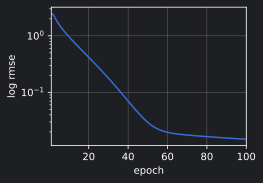

In [348]:
train_and_pred(train_features, test_features, train_labels, test_data, num_epochs, lr, weight_decay, batch_size)

## **Summary**
  * Real-world data typically contains a mix of different data types and requires preprocessing.
  * Common preprocessing methods: rescaling real-valued data to have a mean of zero and a standard deviation of one; replacing missing values with the mean.
  * Converting category features into metric features allows us to treat this feature as a one-hot vector.
  * We can use K-fold cross-validation to select a model and tune the hyperparameters.
  * Logarithms are useful for calculating relative error.